In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import numbers

from scipy.interpolate import interpn

import ipywidgets as widgets
from pathlib import Path

from thermal_loads_261119 import *

In [2]:
# environment settings: 
pd.set_option('display.max_column',None)
pd.set_option('display.max_rows',50)
pd.set_option('display.max_seq_items',None)
pd.set_option('display.max_colwidth', 500)
pd.set_option('expand_frame_repr', True)

np._core.arrayprint.set_printoptions(linewidth= 180)
np.set_printoptions(threshold=np.inf)

# Data

In [3]:
project = 'TVVL'

df0 = pd.read_csv("TVVL_niveau_0_components.csv")
df1 = pd.read_csv("TVVL_niveau_3_components.csv")
df2 = pd.read_csv("TVVL_niveau_3_components.csv")
df3 = pd.read_csv("TVVL_niveau_3_components.csv")
df4 = pd.read_csv("TVVL_niveau_3_components.csv")
df5 = pd.read_csv("TVVL_niveau_5_components.csv")

# Base internal temperatures of the different floors
t_in_values = [20, 20, 20, 20, 20, 20]

In [4]:
frames = [df0, df1, df2, df3, df4, df5]
wl, wd = gather_dataframes(frames)

df_tin = pd.DataFrame({'floor_number': np.arange(len(t_in_values)), 't_in': t_in_values}).set_index('floor_number')
df_tin

,t_in
floor_number,
0,20
1,20
2,20
3,20
4,20
5,20


#### Split foor and roof areas

In [5]:
# Split roof or floor area when floor/roof areas are not identical from one floor to another
split_floors = True

if split_floors:
    wl = wl.copy()
    wl = split_roof_floor(wl, tol=1e-6)
    wl['area_m2'] = wl['area_m2'].round(3)

# Add column of identificators (id) for the detection of floor/roof interfaces : Floor/roof sharing the same area from one floor to another
wl = add_interface_id(wl)

wl.loc[pd.notna(wl['interface_id']) & (wl['id'] != wl['type'])][['floor_number', 'id', 'type', 'interface_id', 'area_m2']]

,floor_number,id,type,interface_id,area_m2
20,1,floor_1,floor,interface_0_1,347.820
21,1,floor_2,floor,ext_floor_1,2.165
52,4,roof_1,roof,interface_4_5,266.365
53,4,roof_2,roof,ext_roof_4,83.620


#### Construction quality level (thermal bridges)
'A' : New building with certified minimization of thermal bridges  
'B' : New building compliant with general codes of practice  
'C' : Building with internal insulation interrupted by solid floor slabs  
'D' : Other buildings  

In [6]:
building_quality = 'B'

#### Heating system (stratification)   
'HAC' : Hot-air heating without additional destratification   
'HAD' : Hot-air heating with additional destratification   
'CRP' : Ceiling-mounted radiant panels   
'RTH' : Radiant tube heating   
'IRH' : Infrared radiant heater   
'SUR' : Integrated surface heat emission   
'RAD' : Radiators   
'NOT' : No heating system specified

In [7]:
heating_syst   = 'RAD'

#### General data

In [8]:
# Postal code
CP = 1000

# Infiltration rate at 50 Pa
n_50  = 1

# Windows U-value
U_wd  = 1.50  #[W/m2/K]

# Skylights U-value
U_sk  = 1.50  #[W/m2/K]

#### Ventilation

In [9]:
# Occupants requirements
q_occ_m3h  = 45 # Fresh air flow per occupant(m³/h.occ)

# Floor area per occupant
A_fl_occ = 10 # Office value

# efficiency of ventilation system heat recovery exchanger
epsilon_hx  = 0.80 

#### Additional Power for Reheating

In [10]:
# Choose between EN12831 Annex F Tables 'F1' or 'F3'
rh_table = 'F1'

# 'L' : Lightweight structure, 'H' : Heavy structure
th_mass = 'H'

# Infiltration rate during setback time (min 0.1 vol/h, max 0.5 vol/h)
n_inf_setback = 0.5

# Heating set back duration (max 168 h for table 'F1')
time_setback_h = 14

# Reheat time in hours (min 0.5 h)
time_reheat_h = 6

# Minimum reheat factor (W/m² of floor heated area)
f_rh_min = 10 # W/m²

#### Wall types layers

In [11]:
materials_list = []

materials_list.append({"material":'concrete_bloc'      ,"lambda":1.36,"rho":2000,"c":1000})
materials_list.append({"material":'insulation'         ,"lambda":0.026,"rho":80, "c":840})
materials_list.append({"material":'reinforced_concrete',"lambda":2.30,"rho":2400,"c":1000})
materials_list.append({"material":'concrete'           ,"lambda":2.10,"rho":2400,"c":1000})
materials_list.append({"material":'brick'              ,"lambda":1.59,"rho":2200,"c":1000})
materials_list.append({"material":'screed'             ,"lambda":1.40,"rho":2000,"c":1000})
materials_list.append({"material":'foamglass'          ,"lambda":0.055,"rho":150,"c":1000})
materials_list.append({"material":'plaster_panel'      ,"lambda":0.32,"rho":1200,"c":1000})
materials_list.append({"material":'EPS_board'          ,"lambda":0.034,"rho":25, "c":1300})

materials = pd.DataFrame(materials_list)

# Wall layers from indoor to outdoor

# Standard insulation

wt_layers = \
[('wall_ext', 0, 0.190, 'concrete_bloc'),
 ('wall_ext', 1, 0.100, 'insulation'),
 
 ('wall_sep', 0, 0.190, 'concrete_bloc'),

 ('transom', 0, 0.01, 'plaster_panel'),
 ('transom', 0, 0.10, 'EPS_board'),
 
 ('roof'    , 0, 0.300, 'reinforced_concrete'),
 ('roof'    , 1, 0.200, 'insulation'),
 
 ('roof_terrace', 0, 0.300, 'reinforced_concrete'),
 ('roof_terrace', 1, 0.120, 'insulation'),
 
 ('floor_gr', 0, 0.070, 'screed'),
 ('floor_gr', 1, 0.300, 'concrete'),
 ('floor_gr', 2, 0.080, 'foamglass'),

 ('floor_ext', 0, 0.070, 'screed'),
 ('floor_ext', 1, 0.400, 'concrete'),

 ('floor_sep_u', 0, 0.070, 'screed'),
 ('floor_sep_u', 1, 0.300, 'concrete'),

 ('floor_sep_i', 0, 0.075, 'screed'),
 ('floor_sep_i', 1, 0.050, 'insulation'),
 ('floor_sep_i', 2, 0.300, 'concrete')
]

# # Reinforced insulation

U_wd  = 1.05

building_quality = 'A'

wt_layers = \
[('wall_ext', 0, 0.190, 'concrete_bloc'),
 ('wall_ext', 1, 0.100, 'insulation'),
 
 ('wall_sep', 0, 0.190, 'concrete_bloc'),

 ('transom', 0, 0.01, 'plaster_panel'),
 ('transom', 0, 0.10, 'EPS_board'),
 
 ('roof'    , 0, 0.300, 'reinforced_concrete'),
 ('roof'    , 1, 0.200*30/20, 'insulation'),
 
 ('roof_terrace', 0, 0.300, 'reinforced_concrete'),
 ('roof_terrace', 1, 0.120*20/12, 'insulation'),
 
 ('floor_gr', 0, 0.070, 'screed'),
 ('floor_gr', 1, 0.300, 'concrete'),
 ('floor_gr', 2, 0.080*10/8, 'foamglass'),

 ('floor_ext', 0, 0.070, 'screed'),
 ('floor_ext', 1, 0.400, 'concrete'),

 ('floor_sep_u', 0, 0.070*6/7, 'screed'),
 ('floor_sep_u', 1, 0.065, 'insulation'),
 ('floor_sep_u', 2, 0.300, 'concrete'),

 ('floor_sep_i', 0, 0.075, 'screed'),
 ('floor_sep_i', 1, 0.050, 'insulation'),
 ('floor_sep_i', 2, 0.300, 'concrete')
]

wt_layers = pd.DataFrame(wt_layers, columns=('wall_type', 'layer', 'thickness', 'material'))
wt_layers = wt_layers.sort_values(['wall_type', 'layer'])
wt_layers = wt_layers.set_index('wall_type')

#### Wall type specificities

In [12]:
wall_types = wt_layers.index.unique()
flag_cols = ['thermal_bridges', 'external_clading', 'adjacent_entity', 'ground_contact']

get_flags = flag_form(wall_types, flag_cols, project + '_env_wt.csv')

Output()

In [13]:
wt_env = get_flags()          # index = wall_types, 4 boolean columns
# wt_env

In [14]:
options_w = sorted(set(wt_layers.index)) + ['']
options_t = ['t_ext', 't_min', 't_avg']  + ['']

#### Walls: wall types and environmental temperatures

In [15]:
wlv = wl.loc[wl['type'] == 'wall']
keys_wlv = ['orientation', 'type']
get_wlv = env_form(wlv, keys_wlv, project + '_env_wlv.csv', options_w, options_t)

Output()

In [16]:
wlv_filled = wlv.merge(get_wlv(), on=keys_wlv, how='left')
# wlv_filled

#### Panels: wall types and environmental temperatures

In [17]:
wlp = wl.loc[wl['type'] == 'panel']
keys_wlp = ['orientation', 'floor_number', 'id', 'width_m', 'height_m', 'sill_height_m']
get_wlp = env_form(wlp, keys_wlp, project + '_env_wlp.csv', options_w, options_t)

Output()

In [18]:
wlp_filled = wlp.merge(get_wlp(), on=keys_wlp, how='left')
# wlp_filled 

#### Floors and roofs: wall types and environmental temperatures

##### Interfaces between floors

In [19]:
wli = wl.loc[(wl['type'].isin(['floor', 'roof'])) & (wl['interface_id'].str.contains('interface', na=False))]
keys_wli = ['interface_id']
get_wli = env_wt_form(wli, keys_wli, project + '_env_wli.csv', options_w)

Output()

In [20]:
wli_filled = wli.merge(get_wli(), on=keys_wli, how='left')
wli_filled = add_t_env(wli_filled, df_tin) 
# wli_filled

##### Floors and roofs not shared between floors

In [21]:
wlh = wl.loc[(wl['type'].isin(['floor', 'roof'])) & (~wl['interface_id'].str.contains('interface', na=False))]
keys_wlh = ['floor_number', 'interface_id', 'area_m2']
get_wlh = env_form(wlh, keys_wlh, project + '_env_wlh.csv', options_w, options_t)

Output()

In [22]:
wlh_filled = wlh.merge(get_wlh(), on=keys_wlh, how='left')
# wlh_filled

In [23]:
wl_filled = pd.concat([wlv_filled, wlp_filled, wli_filled, wlh_filled])
# wl_filled

# Compute and Results

In [24]:
# dfw  : wall data, parameters and heat transmission losses 
# dfwT : heat transmission losses by wall
# dfwtT: heat transmission losses by wall type 
# dfzT: heat transmission losses by zonez and breakdown according to vertical walls, horizontal walls and windows
# dfzpPHI: heat losses and loads by zone with total emission and total production rows
# dfzPHI: heat losses and loads by zone
# dffPHI: heat losses and loads by facade
# dffv : heat losses and loads by facade and by zone


gen_data  = [df_tin, building_quality, heating_syst, CP, n_50, U_wd, U_sk]
vent_data = [q_occ_m3h, A_fl_occ, epsilon_hx]
ctrl_data = [rh_table, th_mass, n_inf_setback, time_setback_h, time_reheat_h, f_rh_min]

dfv          = ventilation_losses(gen_data, vent_data, wl)
dfwt, dfw    = tansmission_losses(gen_data, materials, wt_layers, wt_env, wl_filled, wd, dfv)
dfz          = reheating_loads(gen_data, ctrl_data, dfv, dfw)

dfwT, dfwtT, dfzT, dfzPHI, dfzpPHI  = thermal_loads_by_zone(dfv, dfw, dfz, wt_env)
dffv, dffPHI = thermal_loads_by_facade(dfv, dfw, dfz, wt_env, dfzPHI)

df_gen_data, df_ctrl_data, dfv, dfwt, dfw, dfwT, dfwtT, dfzT, dfzPHI, dfzpPHI= \
                display_tables(gen_data, ctrl_data, dfv, dfw, dfwt, dfwT, dfwtT, dfzT, dfzpPHI, dfzPHI, dffv, dffPHI)

# Graph

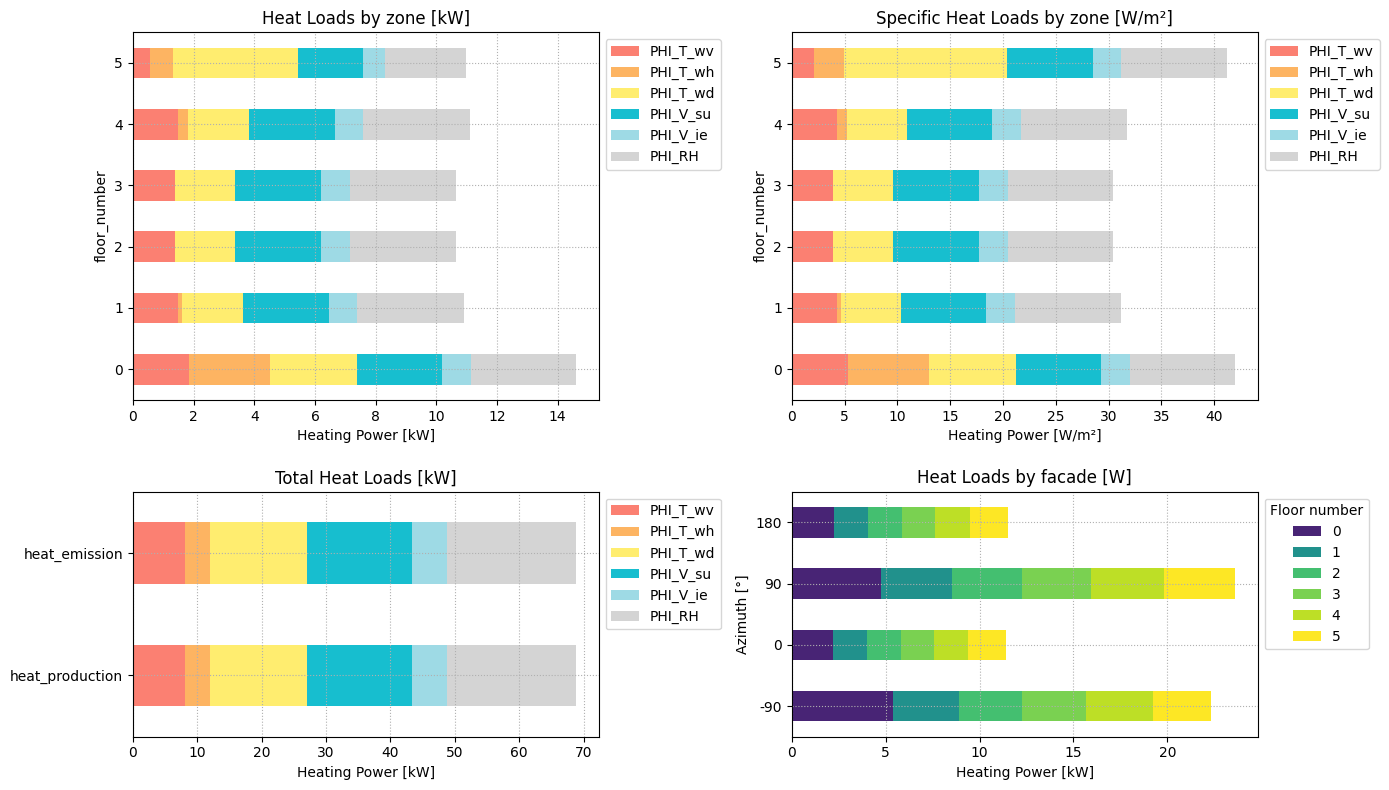

In [25]:
fig, axes = plot_heat_loads(
    dfPHI=dfzpPHI,
    dfv=dfv,
    dffv=dffv,
    display_total=False,
    reverse_order=False
)

# Tables

In [26]:
# Display style for the dataframes
styles = [dict(selector="caption",
                       props=[("text-align", "middle"),
                              ("font-size", "110%"),
                              ("font-weight", "bold"),
                              ("color", 'black'),
                              ("padding-bottom", "10px"),
                              ("white-space", "nowrap")
                             ])]

#### Transmission by wall types

#### Transmission by zone and wall categories

#### Heat Loads by zone and for production 

In [27]:
bold_cols = ['PHI_T', 'PHI_V', 'PHI_TOT', 'PHI_HL']
bold_cols = [col for col in dfzpPHI.columns if col.startswith(tuple([x + ' ' for x in bold_cols]))]

dfzpPHI.style \
    .format("{:.0f}") \
    .set_properties(subset=bold_cols, **{"font-weight": "bold"}) \
    .set_caption("Transmission Ventilation and Total Heat losses - Heat Loads by zone [W]") \
    .set_table_styles(styles)

,PHI_T_wv [W],PHI_T_wh [W],PHI_T_wd [W],PHI_T [W],PHI_V_su [W],PHI_V_ie [W],PHI_V [W],PHI_TOT [W],PHI_RH [W],PHI_HL [W]
floor_number,,,,,,,,,,
0,1853,2661,2864,7377,2817,942,3760,11137,3478,14615
1,1482,144,1991,3617,2835,948,3783,7400,3500,10900
2,1379,0,1991,3370,2835,948,3783,7153,3500,10653
3,1379,0,1991,3370,2835,948,3783,7153,3500,10653
4,1495,328,1991,3813,2835,948,3783,7596,3500,11096
5,559,751,4125,5435,2158,722,2879,8314,2664,10978
heat_emission,8147,3884,14951,26982,16314,5456,21771,48752,20141,68894
heat_production,8147,3884,14951,26982,16314,5456,21771,48752,20141,68894


#### By facade

In [28]:
bold_cols = ['PHI_HL']
bold_cols = [col for col in dffPHI.columns if col.startswith(tuple([x + ' ' for x in bold_cols]))]

dffPHI.style \
    .format("{:.0f}") \
    .set_properties(subset=bold_cols, **{"font-weight": "bold"}) \
    .set_caption("Heat Losses and Heat Loads by facade [W]") \
    .set_table_styles(styles)

,PHI_TOT [W],PHI_HL [W]
azimuth_deg,,
-90,15343,22346
0,8229,11427
90,16899,23625
180,8281,11496


#### Save to Excel

In [29]:
with pd.ExcelWriter(project + "_output.xlsx") as writer: 

    # DATA
    
    # General data
    df_gen_data.to_excel(writer, sheet_name='general_data')

    # Reheat data
    df_ctrl_data.to_excel(writer, sheet_name='control_data') 

    # Materials data
    materials.to_excel(writer, sheet_name='materials_data')

    # Wall types layers data
    wt_layers.to_excel(writer, sheet_name='wall_types_layers_data')

    # Wall types environmental data
    wt_env.to_excel(writer, sheet_name='wall_types_env_data')

    # Walls data
    wl.to_excel(writer, sheet_name='wall_data')

    # Windows data
    wd.to_excel(writer, sheet_name='windows_data')

    # Ventilation data
    dfv.to_excel(writer, sheet_name='ventilation_data') 


    # RESULTS

    # dfwt : Walls thicknesses [m] and conductive resistance [m²K/W]
    dfwt.round(2).to_excel(writer, sheet_name='walls_types') 
    
    # dfw : Walls Areas [m²] - Temperature Factors - U_values [W/m²K] - Heat transmission losses [W]
    dfw.to_excel(writer, sheet_name='walls') 

    # dfwtT: Walls Areas [m²] - Heat transmission losses [W] by zone and wall type
    dfwtT.to_excel(writer, sheet_name='TR_by_walls_types_zone') 

    # dfzT: Wall Areas [m²] - Heat transmission losses [W] by zone
    dfzT.to_excel(writer, sheet_name='TR_by_zone') 

    # dfzPHI  : Heat losses and heat loads by zone [W] (emission and production)
    dfzPHI.to_excel(writer, sheet_name='PHI_by_zone') 

    # dffPHI : Heat losses and loads by facade [W]
    dffPHI.astype(int).to_excel(writer, sheet_name='PHI_by_facade') 